In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

milk = pd.read_csv('../pliki/milk.csv')
milk.head()

,Date,Production
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


In [2]:
milk.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Date        168 non-null    str  
 1   Production  168 non-null    int64
dtypes: int64(1), str(1)
memory usage: 2.8 KB


### średnia

In [3]:
milk["Production"].mean()

np.float64(754.7083333333334)

### maksimum i minimum

In [4]:
milk["Production"].max()

np.int64(969)

In [5]:
milk["Production"].min()


np.int64(553)

### wariancja

In [6]:
milk["Production"].var()

np.float64(10445.764720558882)

### odchylenie standardowe

In [7]:
milk["Production"].std()


np.float64(102.20452397305553)

### mediana

In [8]:
milk["Production"].median()


np.float64(761.0)

### kwartyle

In [9]:
milk["Production"].quantile([0.25, 0.5, 0.75])


0.25    677.75
0.50    761.00
0.75    824.50
Name: Production, dtype: float64

### średnia krocząca

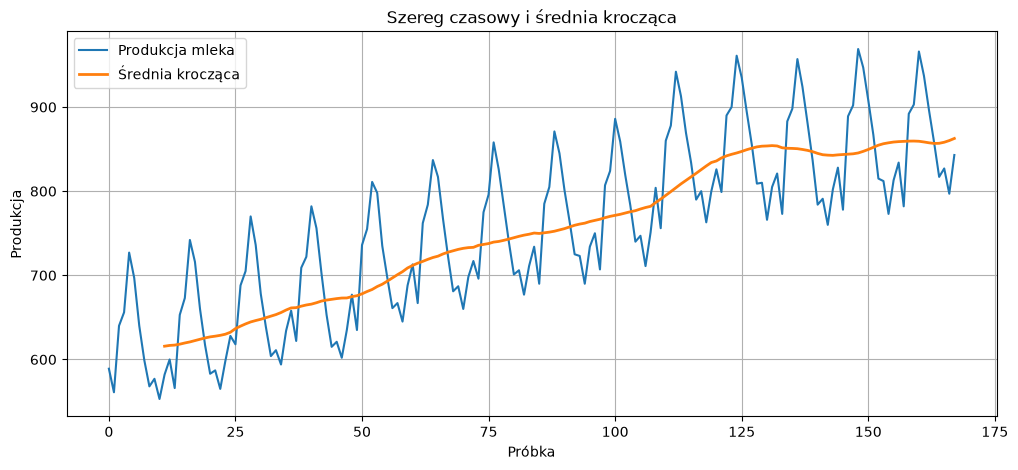

In [10]:
rolling_mean = milk["Production"].rolling(window=12).mean()
rolling_mean
plt.figure(figsize=(12, 5))
plt.plot(milk["Production"], label="Produkcja mleka")
plt.plot(rolling_mean, label="Średnia krocząca", linewidth=2)
plt.title("Szereg czasowy i średnia krocząca")
plt.xlabel("Próbka")
plt.ylabel("Produkcja")
plt.legend()
plt.grid(True)
plt.show()


### odchylenie standardowe kroczące

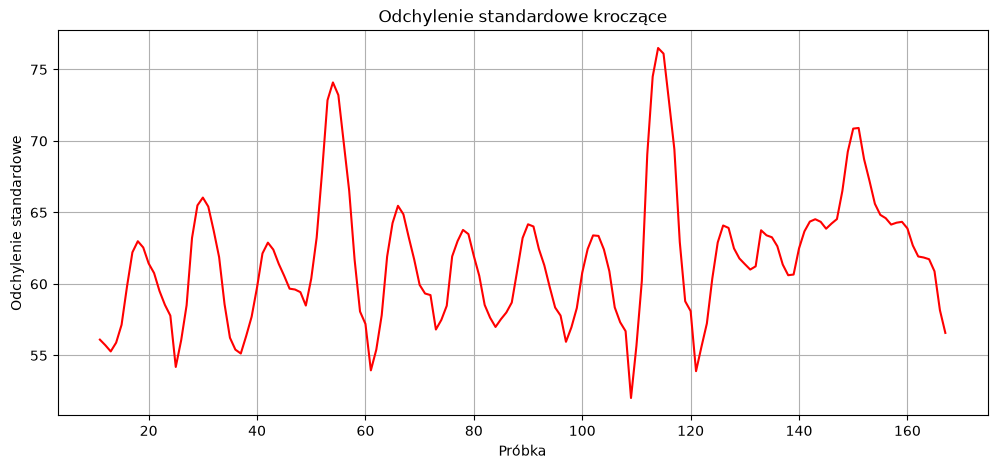

In [11]:
rolling_std = milk["Production"].rolling(window=12).std()
rolling_std
plt.figure(figsize=(12, 5))
plt.plot(rolling_std, color="red")
plt.title("Odchylenie standardowe kroczące")
plt.xlabel("Próbka")
plt.ylabel("Odchylenie standardowe")
plt.grid(True)
plt.show()

### transformata Fouriera

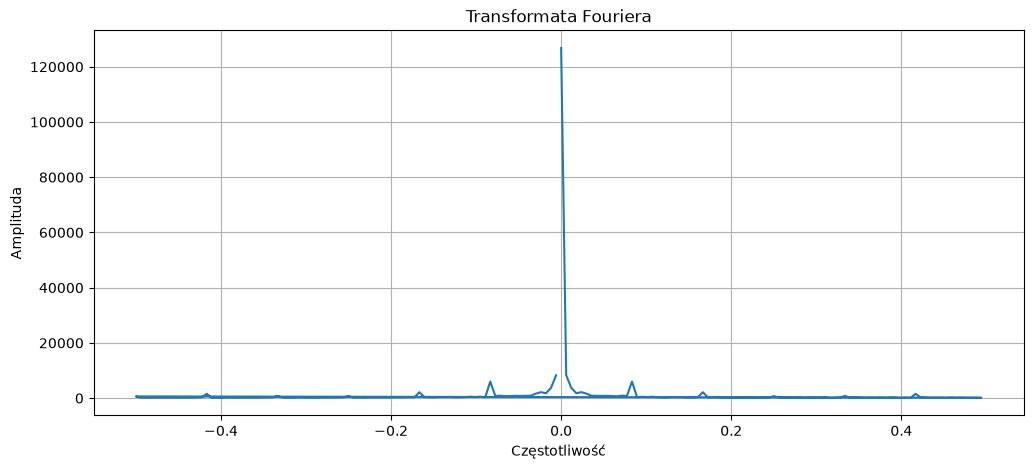

In [12]:
fft = np.fft.fft(milk["Production"])
freq = np.fft.fftfreq(len(milk))
plt.figure(figsize=(12, 5))
plt.plot(freq, np.abs(fft))
plt.title("Transformata Fouriera")
plt.xlabel("Częstotliwość")
plt.ylabel("Amplituda")
plt.grid(True)
plt.show()


### dekompozycja szeregu czasowego

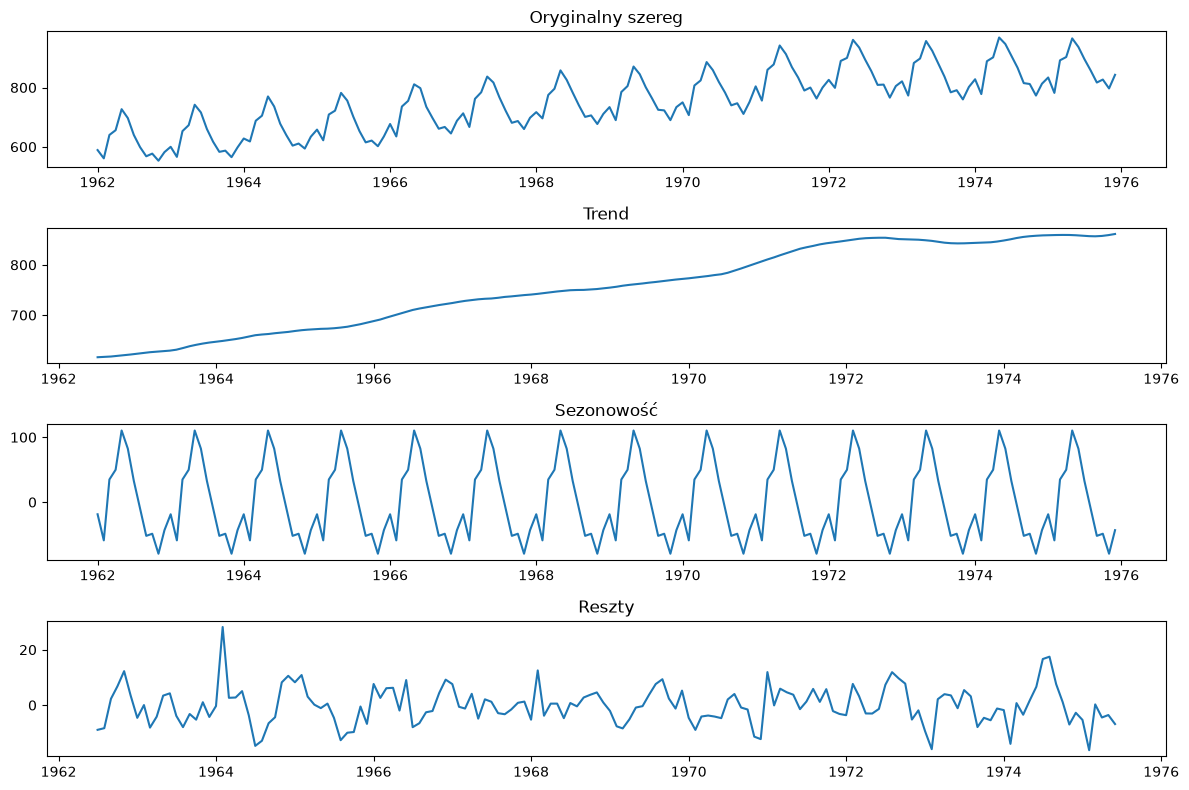

In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose

milk['Date'] = pd.to_datetime(milk['Date'])
milk['Production'] = pd.to_numeric(milk['Production'])

milk = milk.set_index('Date')

decomposition = seasonal_decompose(milk, model='additive', period=12)
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid
plt.figure(figsize=(12, 8))
plt.subplot(4, 1, 1)
plt.plot(milk)
plt.title("Oryginalny szereg")
plt.subplot(4, 1, 2)
plt.plot(trend)
plt.title("Trend")
plt.subplot(4, 1, 3)
plt.plot(seasonal)
plt.title("Sezonowość")
plt.subplot(4, 1, 4)
plt.plot(residual)
plt.title("Reszty")
plt.tight_layout()
plt.show()